# <Center> INF - Deliverable 1

<center> Group: Magnus Bigum and Georg Hagen
<center> Date: 16.10.2026

# Task 1: Temperature

In [72]:
import pandas as pd

import requests

import matplotlib.pyplot as plt 

import yaml

client_id = open('frost_client_id.txt').read().strip()


# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])

rows=[]

for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)

df = pd.concat(rows, ignore_index=True)




Data retrieved from frost.met.no!


In [73]:

def temperature_summary(df):
    summary = pd.DataFrame({
        "Statistics": ["Mean", "Median", "min", "max"],
        "Temperature (°C)": [
            df["value"].mean(),
            df["value"].median(),
            df["value"].min(),
            df["value"].max()
        ]
    })

    print("Temperature Summary - 2025")
    print(summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    ))

temperature_summary(df)



Temperature Summary - 2025
Statistics  Temperature (°C)
      Mean              7.90
    Median              8.35
       min            -16.10
       max             24.50


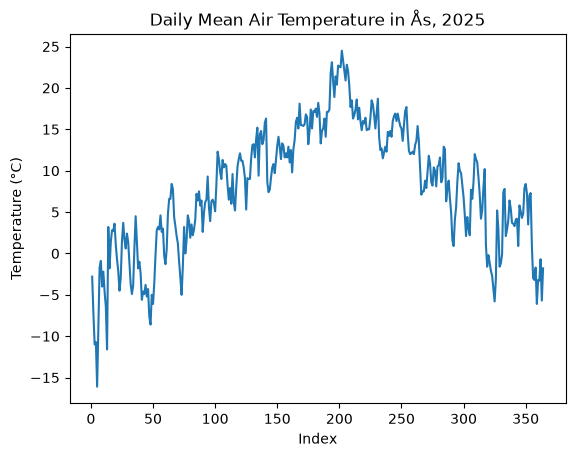

In [74]:
df_pt6h_t = df[df["timeOffset"] == "PT6H"].copy()
df_pt6h_t.index = range(1, len(df_pt6h_t) + 1)

df_pt6h_t.plot(
    y="value",
    kind="line",
    title="Daily Mean Air Temperature in Ås, 2025",
    xlabel="Index",
    ylabel="Temperature (°C)",
    legend=False
)
plt.show()

# Task 2: Precipitation

In [75]:
parameters_2 = {
'sources': 'SN17850',
'elements': 'sum(precipitation_amount P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r_2 = requests.get(endpoint, parameters_2, auth=(client_id,''))
# Extract JSON data
json_2 = r_2.json()

# Check if the request worked, print out any errors
if r_2.status_code == 200:
    data_2 = json_2['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r_2.status_code)
    print('Message: %s' % json_2['error']['message'])
    print('Reason: %s' % json_2['error']['reason'])

rows_2=[]

for i in range(len(data_2)):
    row = pd.DataFrame(data_2[i]['observations'])
    row['referenceTime'] = data_2[i]['referenceTime']
    row['sourceId'] = data_2[i]['sourceId']
    rows_2.append(row)

df_2 = pd.concat(rows_2, ignore_index=True)

Data retrieved from frost.met.no!


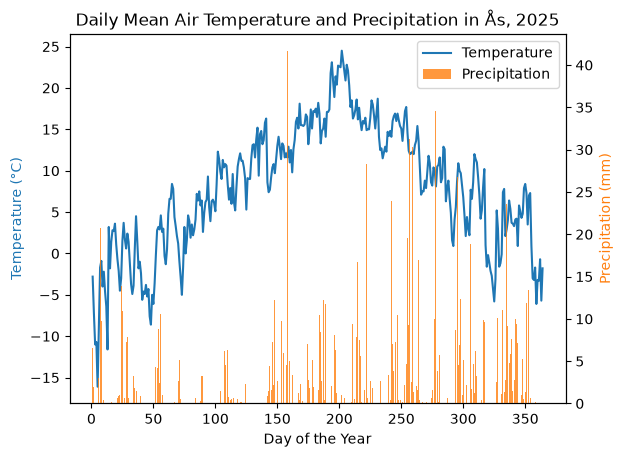

In [76]:
df_pt6h_p = df_2[df_2["timeOffset"] == "PT6H"].copy()
df_pt6h_p.index = range(1, len(df_pt6h_p) + 1)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

line1 = df_pt6h_t.plot(y="value", ax=ax1, color="tab:blue", label="Temperature")
line2 = ax2.bar(
    df_pt6h_p.index,
    df_pt6h_p["value"],
    color="tab:orange",
    alpha=0.8,
    label="Precipitation"
)
ax1.set_title("Daily Mean Air Temperature and Precipitation in Ås, 2025")
ax1.set_xlabel("Day of the Year")
ax1.set_ylabel("Temperature (°C)", color="tab:blue")
ax2.set_ylabel("Precipitation (mm)", color="tab:orange")

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2)


plt.show()

# Task 3: Historical temperature data

In [77]:
# Define endpoint and parameters
parameters_1925 = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '1925-01-01/1925-12-31',
}

r_1925 = requests.get(
    endpoint, params=parameters_1925, auth=(client_id, "")
)

r_1925.raise_for_status()
data_1925 = r_1925.json()["data"]

rows_1925 = []

for day in data_1925:
    row = pd.DataFrame(day["observations"])
    row["referenceTime"] = day["referenceTime"]
    rows_1925.append(row)

if rows_1925:
    df_1925 = pd.concat(rows_1925, ignore_index=True)
else:
    print("No observations found for 1925")

def temperature_summary_1925(df):
    summary = pd.DataFrame({
        "Statistics": ["Mean", "Median", "min", "max"],
        "Temperature (°C)": [
            df["value"].mean(),
            df["value"].median(),
            df["value"].min(),
            df["value"].max()
        ]
    })

    print("Temperature Summary - 1925")
    print(summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    ))


temperature_summary_1925(df_1925)
print("")
temperature_summary(df)

Temperature Summary - 1925
Statistics  Temperature (°C)
      Mean              5.31
    Median              5.30
       min            -20.70
       max             24.30

Temperature Summary - 2025
Statistics  Temperature (°C)
      Mean              7.90
    Median              8.35
       min            -16.10
       max             24.50


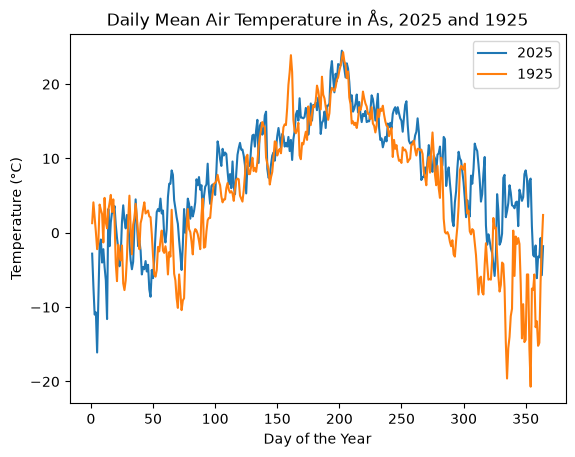

In [78]:
df_pt0h_1925 = df_1925[df_1925["timeOffset"] == "PT0H"].copy()
df_pt0h_1925.index = range(1, len(df_pt0h_1925) + 1)

fig, ax = plt.subplots()

df_pt6h_t.plot(y="value", ax=ax, label="2025", color="tab:blue")
df_pt0h_1925.plot(y="value", ax=ax, label="1925", color="tab:orange")

ax.set_title("Daily Mean Air Temperature in Ås, 2025 and 1925")
ax.set_xlabel("Day of the Year")
ax.set_ylabel("Temperature (°C)")
ax.legend()

plt.show()

# Task 4: Heatwaves

In [79]:
def count_heatwaves(station, year, station_name):

    # Get maximum temperature data
    parameters = {
        "sources": station,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year}-12-31",
        "timeoffsets": "PT0H"
    }

    r = requests.get(endpoint, params=parameters,
                     auth=(client_id, ""), timeout=30)
    r.raise_for_status()

    data = r.json()["data"]

    # Store the daily temperatures
    temperatures = {}

    for day in data:
        date = day["referenceTime"][:10]
        for obs in day["observations"]:
            if obs["timeOffset"] == "PT0H":
                if date in temperatures:
                    raise ValueError("Multiple values for the same day")
                temperatures[date] = obs["value"]

    # Find heatwaves
    heatwaves = []
    days = 0
    start = None

    dates = pd.date_range(f"{year}-01-01", f"{year}-12-31")

    for date in dates:
        day = date.strftime("%Y-%m-%d")
        temp = temperatures.get(day)

        if temp is not None and temp >= 27:
            if days == 0:
                start = day
            days += 1

        else:
            if days >= 5:
                heatwaves.append({
                    "start": start,
                    "end": (date - pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
                    "days": days
                })

            days = 0

    # Check the last days of the year
    if days >= 5:
        heatwaves.append({
            "start": start,
            "end": f"{year}-12-31",
            "days": days
        })

   # Save summary to YAML
    summary = {
    "dates": [
        f"{wave['start']} - {wave['end']}"
        for wave in heatwaves
    ],
    "station_id": station,
    "station_name": station_name,
    "year": year
    }

    with open(f"heatwaves_{station}_{year}.yml", "w") as file:
     yaml.safe_dump(summary, file, sort_keys=False, allow_unicode=True)

    print("Number of heatwaves:", len(heatwaves))

    return summary



count_heatwaves("SN17850", 2025, "Ås")


Number of heatwaves: 1


{'dates': ['2025-07-16 - 2025-07-20'],
 'station_id': 'SN17850',
 'station_name': 'Ås',
 'year': 2025}

# Task 5: Moving average temperature

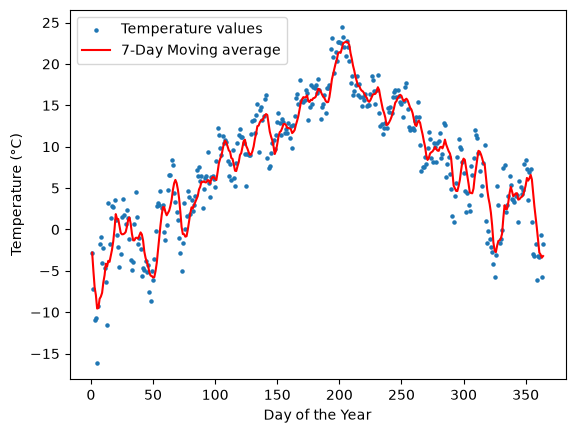

In [44]:
def moving_average(values):
    moving_averages = []
    idx = 0
    while idx < len(values):
        idx_start = idx - 6 if idx >= 6 else 0
        idx_end = idx + 1
        average = sum(values[idx_start:idx_end]) / (idx_end - idx_start)
        moving_averages.append(average)
        idx += 1
    return moving_averages

t_values = df_pt6h_t["value"].tolist()
t_averages = moving_average(t_values)

x = range(1, len(t_values) + 1)

plt.scatter(x, t_values,s=5, label="Temperature values")
plt.plot(x, t_averages, color="red", label="7-Day Moving average")

plt.xlabel("Day of the Year")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.show()